# Human Activity Recognition with a Hidden Markov Model

Infer 4 activities (Still, Standing, Walking, Jumping) from phone accelerometer and gyroscope data using a Gaussian HMM built from scratch in NumPy.

**Pipeline:** load → harmonize to 50 Hz → 2 s windows → features → Z-score → HMM (Baum–Welch) → Viterbi on unseen data

In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.signal import butter, filtfilt

plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True, 'grid.alpha': 0.25})

ACTIVITIES = ['standstill', 'standing', 'walking', 'jumping']        # hidden-state order
NAMES  = ['Still', 'Standing', 'Walking', 'Jumping']
COLORS = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100']
K = len(ACTIVITIES)

TARGET_FS = 50                       # Hz, common sampling rate
TRIM_S    = 0.5                      # s trimmed at each end (tapping start/stop)
WIN, HOP  = 2 * TARGET_FS, TARGET_FS # 2 s windows, 1 s hop (50 % overlap)
TEST_SESSION = 5                     # held-out session = unseen data

os.makedirs('figures', exist_ok=True)
def savefig(name):
    plt.savefig(f'figures/{name}.png', dpi=150, bbox_inches='tight')

## 1. Load raw data
Sensor Logger exports: `Accelerometer` (gravity removed), `TotalAcceleration`, `Gyroscope`, `Metadata`.

In [ ]:
manifest = pd.read_csv('data/recordings_manifest.csv')
SENSORS = {'Accelerometer': 'lin', 'TotalAcceleration': 'acc', 'Gyroscope': 'gyro'}

def load_raw(rec_dir):
    """Return {sensor: DataFrame(t, x, y, z)} with t in seconds, plus the metadata row."""
    out = {}
    for fname, prefix in SENSORS.items():
        df = pd.read_csv(f'{rec_dir}/{fname}.csv').sort_values('time').drop_duplicates('time')
        out[prefix] = pd.DataFrame({'t': df['time'].values / 1e9, 'x': df.x.values, 'y': df.y.values, 'z': df.z.values})
    return out, pd.read_csv(f'{rec_dir}/Metadata.csv').iloc[0]

raw = {}
info = []
for _, r in manifest.iterrows():
    sig, meta = load_raw(f'data/raw/{r.activity}/{r.recording}')
    raw[r.recording] = sig
    info.append({'activity': r.activity, 'device': meta['device name'],
                 'acc_fs': 1 / np.median(np.diff(sig['acc'].t)), 'gyro_fs': 1 / np.median(np.diff(sig['gyro'].t)),
                 'duration_s': min(d.t.iloc[-1] for d in sig.values()) - max(d.t.iloc[0] for d in sig.values())})
info = pd.DataFrame(info)
print('Phone:', ', '.join(info.device.unique()))
info.groupby('activity').agg(files=('device', 'size'), total_s=('duration_s', 'sum'), min_s=('duration_s', 'min'),
                             acc_hz=('acc_fs', 'median'), gyro_hz=('gyro_fs', 'median')).loc[ACTIVITIES].round(1)

Phone: SM-G973F


,files,total_s,min_s,acc_hz,gyro_hz
activity,,,,,
standstill,50,311.3,4.6,100.0,100.0
standing,50,283.2,4.7,100.0,100.0
walking,50,283.9,4.1,100.0,100.0
jumping,50,298.6,3.9,100.0,100.0


## 2. Harmonize and clean
Keep the overlapping time span → trim 0.5 s at each end → low-pass filter at 20 Hz → resample both sensors to **50 Hz** on one timestamp.
50 Hz keeps all human motion (< 20 Hz) and is a rate any phone can record. Cleaned files are saved to `data/clean/`.

200 cleaned recordings saved


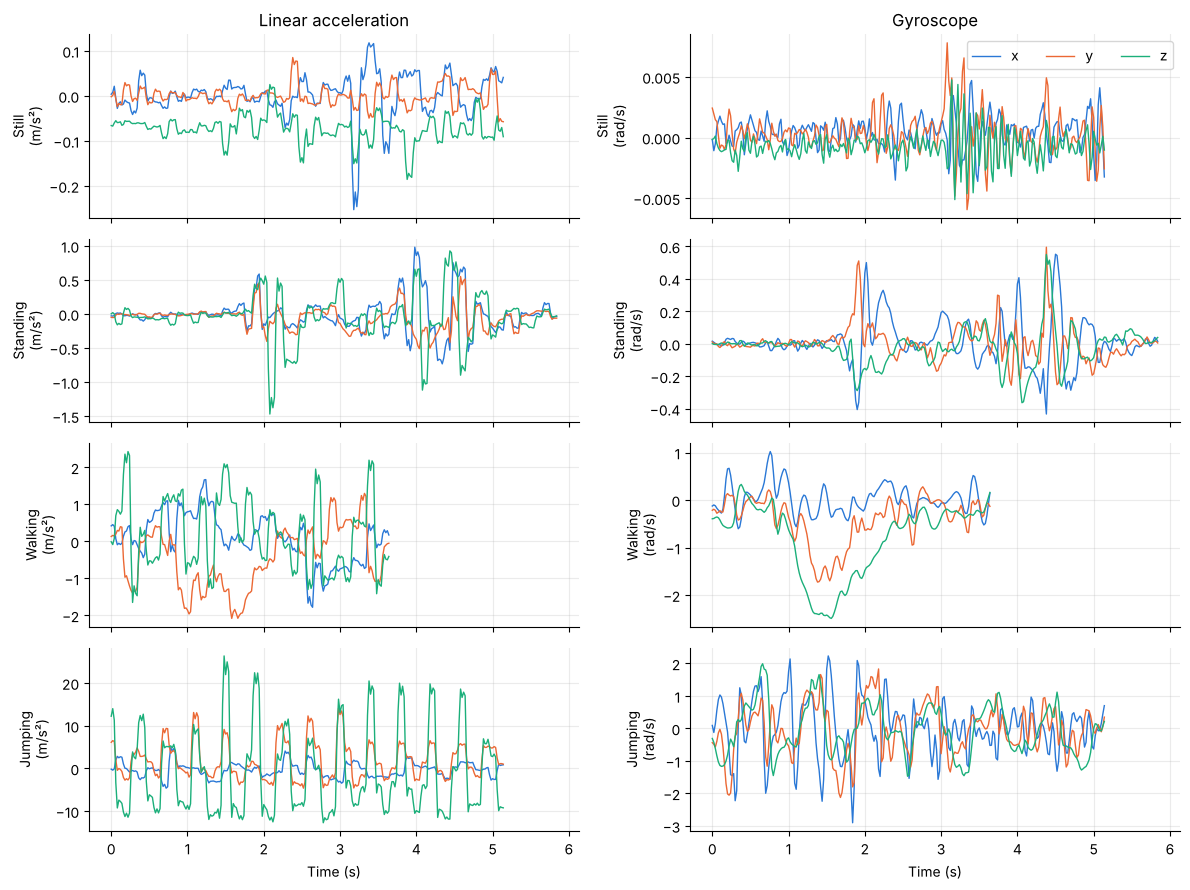

In [ ]:
def harmonize(sig):
    """Align all sensors on one uniform 50 Hz grid (anti-aliased, edges trimmed)."""
    t0 = max(d.t.iloc[0] for d in sig.values()) + TRIM_S
    t1 = min(d.t.iloc[-1] for d in sig.values()) - TRIM_S
    grid = np.arange(t0, t1, 1 / TARGET_FS)
    out = {'timestamp': grid, 'seconds': grid - grid[0]}
    for p, d in sig.items():
        fs = 1 / np.median(np.diff(d.t))
        u = np.arange(d.t.iloc[0], d.t.iloc[-1], 1 / fs)            # uniform grid at the native rate
        b, a = butter(4, 0.4 * TARGET_FS / (fs / 2))                 # 20 Hz anti-alias low-pass
        for ax in 'xyz':
            out[f'{p}_{ax}'] = np.interp(grid, u, filtfilt(b, a, np.interp(u, d.t, d[ax])))
    return pd.DataFrame(out)

clean = {}
for _, r in manifest.iterrows():
    c = harmonize(raw[r.recording]).assign(activity=r.activity)
    os.makedirs(f'data/clean/{r.activity}', exist_ok=True)
    c.to_csv(f'data/clean/{r.activity}/{r.recording}.csv', index=False, float_format='%.6f')
    clean[r.recording] = c
print(len(clean), 'cleaned recordings saved')

fig, axes = plt.subplots(4, 2, figsize=(12, 9), sharex=True)
for i, a in enumerate(ACTIVITIES):
    c = clean[f'{a}_05']
    for j, (p, unit) in enumerate([('lin', 'm/s²'), ('gyro', 'rad/s')]):
        for ax, col in zip('xyz', COLORS):
            axes[i, j].plot(c.seconds, c[f'{p}_{ax}'], lw=1, color=col, label=ax)
        axes[i, j].set_ylabel(f'{NAMES[i]}\n({unit})')
axes[0, 0].set_title('Linear acceleration'); axes[0, 1].set_title('Gyroscope'); axes[0, 1].legend(ncol=3)
axes[-1, 0].set_xlabel('Time (s)'); axes[-1, 1].set_xlabel('Time (s)')
plt.tight_layout(); savefig('01_sample_signals'); plt.show()

## 3. Windows and features
**Window = 2 s (100 samples at 50 Hz), 50 % overlap.** This covers 4–5 walking or jumping cycles (~2–2.5 Hz) and gives an FFT resolution of 0.5 Hz.

**9 features per window**
- Time domain: `acc_std`, `acc_sma`, `acc_range` (jump impacts), `gyro_rms` (Still vs Standing), `corr_acc_yz`
- Frequency domain (FFT): `dom_freq` (rhythm), `spec_energy`, `spec_entropy` (periodic vs noise), `gyro_dom_power`

Intensity features are log-transformed because they span several orders of magnitude.

In [ ]:
FEATURES = ['acc_std', 'acc_sma', 'acc_range', 'gyro_rms', 'corr_acc_yz',
            'dom_freq', 'spec_energy', 'spec_entropy', 'gyro_dom_power']
LOG_FEATURES = ['acc_std', 'acc_sma', 'acc_range', 'gyro_rms', 'spec_energy']

def spectrum(x):
    """One-sided FFT power spectrum (mean removed, Hann window)."""
    x = (x - x.mean()) * np.hanning(len(x))
    return np.fft.rfftfreq(len(x), 1 / TARGET_FS), np.abs(np.fft.rfft(x)) ** 2 / len(x)

def window_features(w):
    lin = w[['lin_x', 'lin_y', 'lin_z']].values
    lin_mag = np.linalg.norm(lin, axis=1)
    acc_mag = np.linalg.norm(w[['acc_x', 'acc_y', 'acc_z']].values, axis=1)
    gyr_mag = np.linalg.norm(w[['gyro_x', 'gyro_y', 'gyro_z']].values, axis=1)

    _, P = spectrum(lin_mag)                       # energy of the body motion
    f, Pa = spectrum(acc_mag)                      # total acc keeps the true step/jump rhythm
    band = (f >= 0.5) & (f <= 20)
    pn = Pa[band] / Pa[band].sum()
    Pg = spectrum(gyr_mag)[1][band]
    corr = np.corrcoef(lin[:, 1], lin[:, 2])[0, 1]
    return {'acc_std': lin_mag.std(),
            'acc_sma': np.abs(lin).sum(axis=1).mean(),
            'acc_range': acc_mag.max() - acc_mag.min(),
            'gyro_rms': np.sqrt(np.mean(gyr_mag ** 2)),
            'corr_acc_yz': np.nan_to_num(corr),
            'dom_freq': f[band][np.argmax(Pa[band])],
            'spec_energy': P.sum(),
            'spec_entropy': -(pn * np.log2(pn + 1e-12)).sum() / np.log2(len(pn)),
            'gyro_dom_power': Pg.max() / Pg.sum()}

rows = []
for _, r in manifest.iterrows():
    c = clean[r.recording]
    for s in range(0, len(c) - WIN + 1, HOP):
        rows.append({'recording': r.recording, 'activity': r.activity, 'session': r.session,
                     **window_features(c.iloc[s:s + WIN])})
windows = pd.DataFrame(rows)
windows[LOG_FEATURES] = np.log10(windows[LOG_FEATURES] + 1e-6)
print(len(windows), 'windows')
windows.groupby('activity')[FEATURES].mean().loc[ACTIVITIES].round(2)

664 windows


,acc_std,acc_sma,acc_range,gyro_rms,corr_acc_yz,dom_freq,spec_energy,spec_entropy,gyro_dom_power
activity,,,,,,,,,
standstill,-1.98,-1.05,-1.44,-2.99,0.13,8.21,-2.73,0.86,0.14
standing,-1.09,-0.68,-0.24,-1.34,-0.12,4.52,-0.97,0.70,0.23
walking,-0.24,0.30,0.54,-0.04,-0.10,2.38,0.75,0.63,0.50
jumping,0.75,1.18,1.58,0.17,0.79,2.50,2.74,0.45,0.20


## 4. Train/test split and normalization
**Session 5 (recordings 41–50 of each activity) is held out as unseen data.**
Z-score using the training data's mean and standard deviation, so every feature has a comparable scale for the Gaussian emissions.

train windows: 527 | unseen test windows: 137


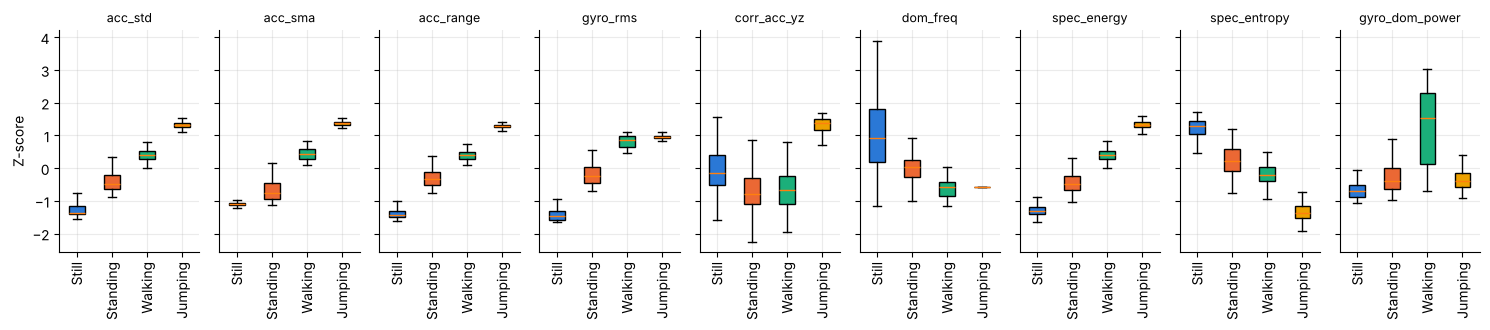

In [ ]:
def zscore(train_mask):
    Z = windows.copy()
    Z[FEATURES] = (windows[FEATURES] - windows.loc[train_mask, FEATURES].mean()) / windows.loc[train_mask, FEATURES].std()
    return Z

train_mask = windows.session != TEST_SESSION
Z = zscore(train_mask)
print('train windows:', train_mask.sum(), '| unseen test windows:', (~train_mask).sum())

fig, axes = plt.subplots(1, len(FEATURES), figsize=(15, 3.4), sharey=True)
for ax, ft in zip(axes, FEATURES):
    bp = ax.boxplot([Z.loc[train_mask & (Z.activity == a), ft] for a in ACTIVITIES],
                    patch_artist=True, showfliers=False)
    for patch, col in zip(bp['boxes'], COLORS): patch.set_facecolor(col)
    ax.set_title(ft, fontsize=9); ax.set_xticks(range(1, K + 1)); ax.set_xticklabels(NAMES, rotation=90)
axes[0].set_ylabel('Z-score')
plt.tight_layout(); savefig('02_feature_boxplots'); plt.show()

### Build observation sequences
Each recording holds one activity, so recordings are chained into realistic routines. For example, Still is only ever followed by Standing.
8 training sequences come from sessions 1–4, and 2 test sequences from session 5.

In [ ]:
ROUTINE = {'standstill': {'standstill': .2, 'standing': .8},
           'standing':   {'standstill': .35, 'standing': .1, 'walking': .45, 'jumping': .1},
           'walking':    {'standing': .4, 'walking': .2, 'jumping': .4},
           'jumping':    {'standing': .3, 'walking': .55, 'jumping': .15}}

def build_sequence(recs, rng):
    """Order single-activity recordings into a realistic routine (each recording used once)."""
    pool = {a: [r for r in recs if r.startswith(a + '_')] for a in ACTIVITIES}
    left = {a: len(v) for a, v in pool.items()}

    def dfs(cur, acts):                                  # random walk with backtracking
        if not any(left.values()): return acts
        opts = ([(a, p * left[a]) for a, p in ROUTINE[cur].items() if left[a]] if cur
                else [(a, left[a]) for a in ACTIVITIES if left[a]])
        while opts:
            w = np.array([p for _, p in opts])
            a = opts.pop(rng.choice(len(opts), p=w / w.sum()))[0]
            left[a] -= 1
            res = dfs(a, acts + [a])
            if res: return res
            left[a] += 1

    return [pool[a].pop() for a in dfs(None, [])]

def make_sequences(sessions, Z, rng):
    """Two routines per session (5 recordings of each activity) -> list of (X, y, df, order)."""
    seqs = []
    for s in sessions:
        recs = sorted(manifest[manifest.session == s].recording)
        for half in (0, 1):
            group = [r for a in ACTIVITIES for r in [x for x in recs if x.startswith(a + '_')][half * 5:(half + 1) * 5]]
            order = build_sequence(group, rng)
            df = pd.concat([Z[Z.recording == r] for r in order], ignore_index=True)
            seqs.append((df[FEATURES].values, df.activity.map(ACTIVITIES.index).values, df, order))
    return seqs

rng = np.random.default_rng(7)
train_seqs = make_sequences([s for s in range(1, 6) if s != TEST_SESSION], Z, rng)
test_seqs = make_sequences([TEST_SESSION], Z, rng)

os.makedirs('data/test_sequences', exist_ok=True)
for i, (_, y, _, order) in enumerate(test_seqs, 1):         # save the 2 unseen test files
    pd.concat([clean[r].assign(recording=r) for r in order]).to_csv(
        f'data/test_sequences/test_sequence_{i}.csv', index=False, float_format='%.6f')
    print(f'Test sequence {i}: {len(order)} recordings, {len(y)} windows')

Test sequence 1: 20 recordings, 68 windows
Test sequence 2: 20 recordings, 69 windows


## 5. HMM (NumPy, from scratch)
| Component | Here |
|---|---|
| States Z | Still, Standing, Walking, Jumping |
| Observations X | 9-D feature vector per window |
| A | 4×4 transition matrix |
| B | Gaussian per state (mean, full covariance) |
| π | initial state probabilities |

- **Baum–Welch** trains the model and stops when the change in log-likelihood is < ε = 10⁻³.
- **Viterbi** decodes the most likely activity sequence, which is what the per-window metrics need.

In [ ]:
def safe_log(p):
    return np.log(np.clip(p, 1e-300, None))

def logsumexp(a, axis):
    m = np.max(a, axis=axis, keepdims=True)
    return np.squeeze(m + np.log(np.sum(np.exp(a - m), axis=axis, keepdims=True)), axis=axis)


class GaussianHMM:
    """HMM with full-covariance Gaussian emissions."""

    def __init__(self, n_states, reg=1e-3):
        self.K, self.reg, self.history = n_states, reg, []

    def log_emission(self, X):
        """log N(x_t | mu_k, Sigma_k) -> array (T, K)."""
        out = np.empty((len(X), self.K))
        for k in range(self.K):
            L = np.linalg.cholesky(self.covs[k])
            maha = np.sum(np.linalg.solve(L, (X - self.means[k]).T) ** 2, axis=0)
            out[:, k] = -0.5 * (X.shape[1] * np.log(2 * np.pi) + 2 * np.log(np.diag(L)).sum() + maha)
        return out

    def init_from_labels(self, seqs):
        """Initial pi, A, means, covariances from labelled sequences (add-one smoothing on counts)."""
        pi, A = np.ones(self.K), np.ones((self.K, self.K))
        for _, y, *_ in seqs:
            pi[y[0]] += 1
            np.add.at(A, (y[:-1], y[1:]), 1)
        self.pi, self.A = pi / pi.sum(), A / A.sum(1, keepdims=True)
        X = np.vstack([s[0] for s in seqs]); y = np.concatenate([s[1] for s in seqs])
        self.means = np.array([X[y == k].mean(0) for k in range(self.K)])
        self.covs = np.array([np.cov(X[y == k].T) + self.reg * np.eye(X.shape[1]) for k in range(self.K)])
        return self

    def forward_backward(self, X):
        """Log-space forward-backward -> (log-likelihood, gamma, xi)."""
        logB, logA = self.log_emission(X), safe_log(self.A)
        T = len(X)
        la, lb = np.empty((T, self.K)), np.zeros((T, self.K))
        la[0] = safe_log(self.pi) + logB[0]
        for t in range(1, T):
            la[t] = logB[t] + logsumexp(la[t - 1][:, None] + logA, axis=0)
        for t in range(T - 2, -1, -1):
            lb[t] = logsumexp(logA + logB[t + 1] + lb[t + 1], axis=1)
        ll = logsumexp(la[-1], axis=0)
        gamma = np.exp(la + lb - ll)
        xi = np.exp(la[:-1, :, None] + logA + (logB[1:] + lb[1:])[:, None, :] - ll)
        return ll, gamma, xi

    def viterbi(self, X):
        """Most likely state sequence."""
        logB, logA = self.log_emission(X), safe_log(self.A)
        T = len(X)
        delta, psi = np.empty((T, self.K)), np.zeros((T, self.K), dtype=int)
        delta[0] = safe_log(self.pi) + logB[0]
        for t in range(1, T):
            cand = delta[t - 1][:, None] + logA
            psi[t] = cand.argmax(0)
            delta[t] = cand.max(0) + logB[t]
        path = [delta[-1].argmax()]
        for t in range(T - 1, 0, -1):
            path.append(psi[t, path[-1]])
        return np.array(path[::-1])

    def baum_welch(self, seqs, tol=1e-3, max_iter=500, verbose=True):
        """EM on unlabelled sequences; stops when the log-likelihood gain is < tol."""
        prev = -np.inf
        for it in range(1, max_iter + 1):
            pi_acc, A_num = np.zeros(self.K), np.zeros((self.K, self.K))
            stats, total = [], 0.0
            for X in seqs:                                           # E-step
                ll, gamma, xi = self.forward_backward(X)
                total += ll; pi_acc += gamma[0]; A_num += xi.sum(0); stats.append((X, gamma))
            self.history.append(total)
            if verbose: print(f'iter {it}: log-likelihood = {total:.4f}')
            if total - prev < tol:                                   # convergence check
                if verbose: print(f'Converged: change {total - prev:.6f} < {tol}')
                self.n_iter_ = it
                return self
            prev = total
            # M-step
            self.pi = (pi_acc + 1) / (pi_acc.sum() + self.K)
            self.A = A_num / A_num.sum(1, keepdims=True)
            Xall = np.vstack([X for X, _ in stats]); G = np.vstack([g for _, g in stats])
            self.means = (G.T @ Xall) / G.sum(0)[:, None]
            self.covs = np.array([((G[:, k, None] * (Xall - self.means[k])).T @ (Xall - self.means[k])) / G[:, k].sum()
                                  + self.reg * np.eye(Xall.shape[1]) for k in range(self.K)])
        self.n_iter_ = max_iter
        return self

### Training: initialize from labels, then run Baum–Welch

iter 1: log-likelihood = 1465.6943
iter 2: log-likelihood = 1471.6096
iter 3: log-likelihood = 1471.6976
iter 4: log-likelihood = 1471.7319
iter 5: log-likelihood = 1471.7472
iter 6: log-likelihood = 1471.7540
iter 7: log-likelihood = 1471.7572
iter 8: log-likelihood = 1471.7587
iter 9: log-likelihood = 1471.7594
Converged: change 0.000714 < 0.001


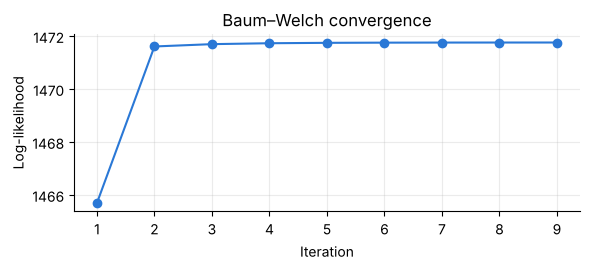

In [ ]:
hmm = GaussianHMM(K).init_from_labels(train_seqs)
hmm.baum_welch([X for X, *_ in train_seqs])

fig, ax = plt.subplots(figsize=(6, 2.8))
ax.plot(range(1, len(hmm.history) + 1), hmm.history, 'o-', color=COLORS[0])
ax.set(xlabel='Iteration', ylabel='Log-likelihood', title='Baum–Welch convergence')
plt.tight_layout(); savefig('03_baum_welch_convergence'); plt.show()

### Learned π, A and emission probabilities

π = {'Still': np.float64(0.083), 'Standing': np.float64(0.25), 'Walking': np.float64(0.417), 'Jumping': np.float64(0.25)}


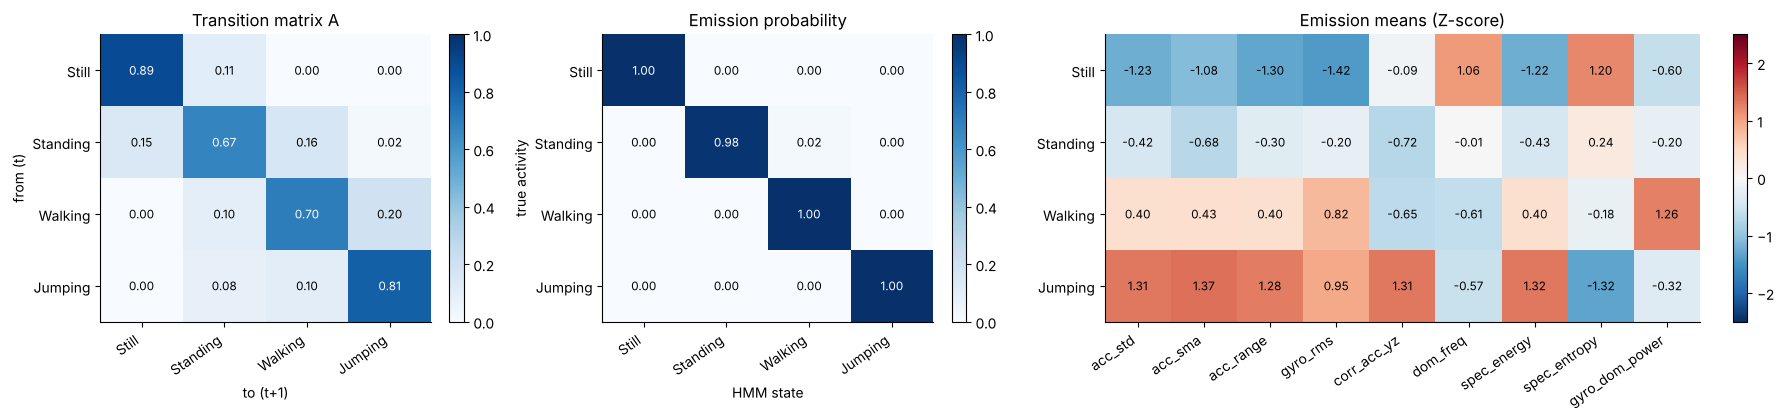

In [ ]:
def heat(ax, M, xt, yt, title, fmt='{:.2f}', cmap='Blues', vmin=None, vmax=None):
    im = ax.imshow(M, cmap=cmap, vmin=vmin, vmax=vmax, aspect='auto')
    ax.set_xticks(range(len(xt))); ax.set_xticklabels(xt, rotation=35, ha='right')
    ax.set_yticks(range(len(yt))); ax.set_yticklabels(yt); ax.set_title(title); ax.grid(False)
    hi = np.abs(M).max() if vmax is None else vmax
    for i in range(M.shape[0]):
        for j in range(M.shape[1]):
            ax.text(j, i, fmt.format(M[i, j]), ha='center', va='center', fontsize=8.5,
                    color='white' if abs(M[i, j]) > 0.6 * hi else 'black')
    plt.colorbar(im, ax=ax, fraction=.046)

print('π =', dict(zip(NAMES, hmm.pi.round(3))))

# emission probability: average normalized N(x | mu_k, Sigma_k) over each activity's training windows
Xtr = np.vstack([s[0] for s in train_seqs]); ytr = np.concatenate([s[1] for s in train_seqs])
lb = hmm.log_emission(Xtr)
post = np.exp(lb - logsumexp(lb, axis=1)[:, None])
B = np.array([post[ytr == k].mean(0) for k in range(K)])

fig, ax = plt.subplots(1, 3, figsize=(18, 4.3), gridspec_kw={'width_ratios': [1, 1, 1.8]})
heat(ax[0], hmm.A, NAMES, NAMES, 'Transition matrix A', vmin=0, vmax=1)
ax[0].set(xlabel='to (t+1)', ylabel='from (t)')
heat(ax[1], B, NAMES, NAMES, 'Emission probability', vmin=0, vmax=1)
ax[1].set(xlabel='HMM state', ylabel='true activity')
heat(ax[2], hmm.means, FEATURES, NAMES, 'Emission means (Z-score)', cmap='RdBu_r', vmin=-2.5, vmax=2.5)
plt.tight_layout(); savefig('04_transition_emission'); plt.show()

## 6. Evaluation on unseen data (session 5)
Sensitivity = TP/(TP+FN) · Specificity = TN/(TN+FP) · Accuracy = (TP+TN)/N

In [ ]:
def evaluate(y_true, y_pred):
    cm = np.zeros((K, K), dtype=int)
    np.add.at(cm, (y_true, y_pred), 1)
    N, rows = cm.sum(), []
    for k in range(K):
        TP = cm[k, k]; FN = cm[k].sum() - TP; FP = cm[:, k].sum() - TP; TN = N - TP - FN - FP
        rows.append({'State (Activity)': NAMES[k], 'Number of Samples': cm[k].sum(),
                     'Sensitivity': TP / (TP + FN), 'Specificity': TN / (TN + FP), 'Overall Accuracy': (TP + TN) / N})
    return pd.DataFrame(rows).round(3), cm

paths = [hmm.viterbi(X) for X, *_ in test_seqs]
y_true = np.concatenate([y for _, y, *_ in test_seqs]); y_pred = np.concatenate(paths)
table, cm = evaluate(y_true, y_pred)
print(f'Overall accuracy on unseen data: {np.mean(y_true == y_pred):.3f}')
table.to_csv('figures/metrics_table.csv', index=False)
table

Overall accuracy on unseen data: 1.000


,State (Activity),Number of Samples,Sensitivity,Specificity,Overall Accuracy
0,Still,39,1.0,1.0,1.0
1,Standing,29,1.0,1.0,1.0
2,Walking,35,1.0,1.0,1.0
3,Jumping,34,1.0,1.0,1.0


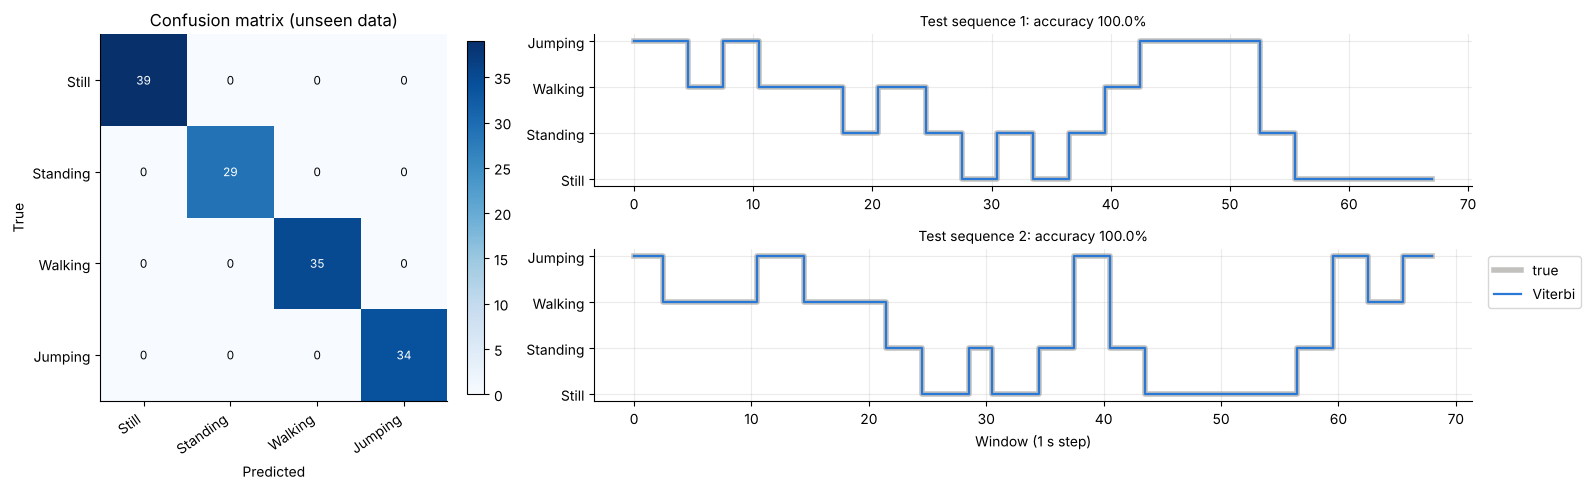

In [ ]:
fig = plt.figure(figsize=(16, 5))
ax = fig.add_subplot(1, 3, 1)
heat(ax, cm, NAMES, NAMES, 'Confusion matrix (unseen data)', fmt='{:d}')
ax.set(xlabel='Predicted', ylabel='True')
for i, ((X, y, *_), path) in enumerate(zip(test_seqs, paths)):
    ax = fig.add_subplot(2, 3, (2, 3) if i == 0 else (5, 6))
    ax.step(range(len(y)), y, where='mid', color='#9a9994', lw=4, alpha=.6, label='true')
    ax.step(range(len(y)), path, where='mid', color=COLORS[0], lw=1.6, label='Viterbi')
    ax.set_yticks(range(K)); ax.set_yticklabels(NAMES)
    ax.set_title(f'Test sequence {i + 1}: accuracy {np.mean(path == y):.1%}', fontsize=10)
ax.set_xlabel('Window (1 s step)'); ax.legend(loc='upper left', bbox_to_anchor=(1.01, 1))
plt.tight_layout(); savefig('05_confusion_and_decoded'); plt.show()

### Extra check: leave-one-session-out
Each session is held out in turn, and the whole pipeline is retrained each time. This gives a more reliable estimate than a single test session.

In [ ]:
cv_cm, cv_acc = np.zeros((K, K), dtype=int), []
for s in range(1, 6):
    Zs = zscore(windows.session != s)
    rng_s = np.random.default_rng(s)
    tr = make_sequences([x for x in range(1, 6) if x != s], Zs, rng_s)
    te = make_sequences([s], Zs, rng_s)
    m = GaussianHMM(K).init_from_labels(tr).baum_welch([X for X, *_ in tr], verbose=False)
    yt = np.concatenate([y for _, y, *_ in te]); yp = np.concatenate([m.viterbi(X) for X, *_ in te])
    cv_cm += evaluate(yt, yp)[1]; cv_acc.append(np.mean(yt == yp))
print('Accuracy per held-out session:', np.round(cv_acc, 3))
print(f'Overall: {np.trace(cv_cm) / cv_cm.sum():.3f}')
pd.DataFrame(cv_cm, index=NAMES, columns=NAMES)

Accuracy per held-out session: [0.973 0.983 0.993 1.    1.   ]
Overall: 0.989


,Still,Standing,Walking,Jumping
Still,184,0,0,0
Standing,0,146,6,0
Walking,0,0,157,0
Jumping,0,0,1,170
